# 07 - Water Saturation

**Part A - Petrophys Curriculum**

Water saturation ($S_w$) is the fraction of the pore space occupied by formation
water. It is the single most consequential number in a petrophysical evaluation:
the hydrocarbon saturation is simply $S_h = 1 - S_w$, and everything downstream -
net pay, bulk-volume water, volumetrics - flows from it.

This notebook is the centrepiece of Part A. We build up from the classic **Archie**
equation for clean formations, then work through the four main **shaly-sand**
corrections (Simandoux, Indonesia, Waxman-Smits, Dual-Water), compare them head to
head on a real shaly interval, derive Archie's $m$ and $n$ from a **Pickett plot**,
compute flushed-zone saturation $S_{xo}$, and finally show how the model choice
changes when we move from a **clastic** reservoir to a **carbonate** one.

## Learning goals

By the end of this notebook you will be able to:

- State the Archie equation and its assumptions, and know when it breaks down.
- Explain the physical idea behind each shaly-sand model and choose between them.
- Run `archie`, `simandoux`, `indonesia`, `waxman_smits`, `dual_water`,
  `calculate_sw` and `calculate_sxo` from `petrophys.petrophysics.saturation`.
- Overlay the models on a real interval, read off their divergence, and reason
  about which to trust.
- Build a Pickett plot and read $m$ (and $R_w$) off the water line.
- Compute flushed-zone saturation $S_{xo}$ and understand what it tells you.
- Select an Sw model for a **carbonate** reservoir using the well's own header
  Archie parameters, and contrast it with the clastic workflow.

## Why this matters

Resistivity logs do not measure hydrocarbons - they measure how hard it is for an
electric current to pass through the rock. Water conducts; hydrocarbons and the
rock matrix do not. Archie's insight (1942) was that in a **clean, water-wet**
rock the resistivity relates to porosity and water saturation through simple power
laws:

$$ S_w^{\,n} = \frac{a\,R_w}{\phi^{m}\,R_t} $$

- $R_t$ - true (deep) formation resistivity, $\Omega\!\cdot\!m$
- $R_w$ - formation-water resistivity, $\Omega\!\cdot\!m$
- $\phi$ - porosity (effective, v/v)
- $a$ - tortuosity factor (often 1)
- $m$ - cementation exponent (~2 for clean sands)
- $n$ - saturation exponent (~2, water-wet)

The trouble: **clay** is also conductive (it holds bound water and has surface
charge). In a shaly sand Archie reads the clay conductivity as if it were extra
formation water and reports $S_w$ that is **too high** (too pessimistic). The
shaly-sand models exist to remove that clay conductivity term in different ways.

### Prerequisites

This notebook assumes you have worked through the earlier Part A notebooks on data
access, clay volume (`Vcl`) and porosity. We recompute `Vcl` and effective
porosity inline here from the raw logs so the notebook runs standalone, but the
methods themselves are covered in those notebooks.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las

print('petrophys', petrophys.__version__)
print('geolink samples :', petrophys.list_samples('geolink'))
print('costa samples[:4]:', petrophys.list_samples('costa')[:4])

petrophys 0.1.0
geolink samples : ['15_9-14', '16_7-1', '25_5-1', '30_6-5']
costa samples[:4]: ['HW-10', 'HW-24', 'HW-25', 'HW-26']


## 1. Load the teaching well and rebuild the input curves

Our clastic teaching well is **30/6-5** (North Sea, depths in metres). The core
data and the BAAT Group sandstone reservoir both sit around 2841-2958 m, so we
focus there. We rebuild the three inputs every saturation model needs:

1. **Vcl** - clay volume from the linear gamma-ray method.
2. **PHIE** - effective porosity from the density and neutron logs.
3. **Rt** - the deep resistivity `RDEP`.

In [2]:
from petrophys.clay_volume import vcl_from_gr
from petrophys.petrophysics.porosity import density_porosity, neutron_porosity

well = read_las(petrophys.sample('30_6-5'))
print('Well          :', well.name)
print('Depth unit    :', well.depth_unit)
print('Curves        :', well.curves)

# Reservoir interval (BAAT GP. sandstone, cored)
TOP, BASE = 2841.0, 2958.0
res = well.depth_slice(TOP, BASE)

depth = res.depth
gr    = res.get('GR').data
rhob  = res.get('RHOB').data
nphi  = res.get('NPHI').data
rt    = res.get('RDEP').data

# 1) Clay volume from GR (linear). Anchor the clean/shale lines on percentiles.
gr_clean = np.nanpercentile(gr, 5)
gr_shale = np.nanpercentile(gr, 95)
vcl = vcl_from_gr(gr, gr_clean, gr_shale)

# 2) Effective porosity: simple density-neutron average, clipped to a physical band.
phid = density_porosity(rhob, rhob_matrix=2.65, rhob_fluid=1.0)
phin = neutron_porosity(nphi)
phie = np.clip((phid + phin) / 2.0, 0.0, 0.40)

print()
print('Interval %.0f - %.0f m (%d samples)' % (TOP, BASE, res.n_samples))
print('GR clean / shale lines : %.1f / %.1f gAPI' % (gr_clean, gr_shale))
print('Vcl  mean/min/max      : %.2f / %.2f / %.2f' %
      (np.nanmean(vcl), np.nanmin(vcl), np.nanmax(vcl)))
print('PHIE mean/min/max      : %.3f / %.3f / %.3f' %
      (np.nanmean(phie), np.nanmin(phie), np.nanmax(phie)))
print('Rt   mean/min/max      : %.1f / %.1f / %.1f ohm.m' %
      (np.nanmean(rt), np.nanmin(rt), np.nanmax(rt)))

Well          : 30/6-5
Depth unit    : m
Curves        : ['LITHOLOGY_GEOLINK', 'CALI', 'DRHO', 'NPHI', 'RHOB', 'PEF', 'GR', 'DTC', 'DTE', 'RDEP', 'SP', 'RSHA', 'RMED', 'BS', 'PHIC', 'GDEN', 'KH_CORE', 'KV_CORE', 'SWC', 'SOC']

Interval 2841 - 2958 m (768 samples)
GR clean / shale lines : 26.2 / 106.5 gAPI
Vcl  mean/min/max      : 0.46 / 0.01 / 1.00
PHIE mean/min/max      : 0.211 / 0.070 / 0.400
Rt   mean/min/max      : 8.3 / 0.8 / 135.2 ohm.m


## 2. Archie - the clean-formation baseline

For a **clean** rock (little to no clay) Archie is all you need:

$$ S_w = \left( \frac{a\,R_w}{\phi^{m}\,R_t} \right)^{1/n} $$

The signature is `archie(rt, rw, phi, a=1.0, m=2.0, n=2.0)`. We need a value for
$R_w$; for this Jurassic sand a value near $0.03\,\Omega\!\cdot\!m$ at reservoir
temperature is reasonable. We start with the textbook $a=1, m=2, n=2$.

**Assumptions baked into Archie:**

- The rock is clean (no conductive clay).
- The rock is water-wet and the pore network is well connected.
- $R_w$, $m$, $n$ are known and roughly constant over the interval.

When clay is present these assumptions fail and Archie over-estimates $S_w$.

In [3]:
from petrophys.petrophysics.saturation import archie

RW = 0.03  # ohm.m at reservoir temperature (illustrative)
A, M, N = 1.0, 2.0, 2.0

sw_archie = archie(rt, RW, phie, a=A, m=M, n=N)

print('Archie Sw  mean : %.3f' % np.nanmean(sw_archie))
print('Archie Sw  p10  : %.3f  (cleanest / most hydrocarbon-bearing)'
      % np.nanpercentile(sw_archie, 10))
print('Archie Sw  p90  : %.3f  (wettest)' % np.nanpercentile(sw_archie, 90))
print()
print('Hydrocarbon saturation Sh = 1 - Sw, mean : %.3f'
      % (1 - np.nanmean(sw_archie)))

Archie Sw  mean : 0.426
Archie Sw  p10  : 0.165  (cleanest / most hydrocarbon-bearing)
Archie Sw  p90  : 0.637  (wettest)

Hydrocarbon saturation Sh = 1 - Sw, mean : 0.574


## 3. Shaly-sand models - four ways to remove the clay conductivity

Each model adds a term that accounts for the extra current the clay carries, so
that only the *free* formation water is counted. They differ in **how** they model
that clay path and in **what inputs** they need.

| Model | Core idea | Extra inputs | Best when |
|-------|-----------|--------------|-----------|
| **Simandoux** | Adds a parallel clay-conductance term $V_{cl}/R_{cl}$ | $V_{cl}, R_{cl}$ | Higher salinity ($\gtrsim$ 20 kppm), dispersed clay |
| **Indonesia** (Poupon-Leveaux) | Clay and sand conductance combine as square roots, weighted by $V_{cl}$ | $V_{cl}, R_{cl}$ | Fresher water, laminated/dispersed clay |
| **Waxman-Smits** | Clay conductivity from cation-exchange capacity (CEC) on **total** porosity | $\phi_t, CEC, B$ | SCAL/CEC data available |
| **Dual-Water** | Splits pore water into free water ($R_w$) and clay-bound water ($R_{wb}$) | $\phi_t, R_{wb}, \phi_{cl}$ | Any shaly rock; robust default |

Below are the exact library signatures we will call.

In [4]:
from petrophys.petrophysics.saturation import (
    simandoux, indonesia, waxman_smits, dual_water,
)

# Estimate a clay resistivity Rcl from the shaliest samples in the interval.
shale_mask = vcl > 0.6
rcl = float(np.nanmean(rt[shale_mask])) if np.any(shale_mask) else 5.0
print('Estimated Rcl (mean Rt where Vcl>0.6) : %.2f ohm.m' % rcl)

# 1) Simandoux : simandoux(rt, rw, phi, vcl, rcl, a, m, n)
sw_sim = simandoux(rt, RW, phie, vcl, rcl, a=A, m=M, n=N)

# 2) Indonesia : indonesia(rt, rw, phi, vcl, rcl, a, m, n)
sw_indo = indonesia(rt, RW, phie, vcl, rcl, a=A, m=M, n=N)

# 3) Waxman-Smits : waxman_smits(phi_t, rt, rw, cec, rho_ma, b_coeff, m_star, n)
#    CEC is meq/g (NOT meq/100g); B is the counter-ion conductance.
CEC, RHO_MA, B_COEFF, M_STAR = 0.10, 2.65, 0.045, 2.0
sw_ws = waxman_smits(phie, rt, RW, CEC, RHO_MA, B_COEFF, m_star=M_STAR, n=N)

# 4) Dual-Water : dual_water(phi_t, rt, rw, rwb, vcl, phi_cl, a, m, n)
#    Bound-water resistivity Rwb ~ 0.3*Rw is a common first guess.
RWB, PHI_CL = 0.3 * RW, 0.30
sw_dw = dual_water(phie, rt, RW, RWB, vcl, PHI_CL, a=A, m=M, n=N)

for name, sw in [('Archie', sw_archie), ('Simandoux', sw_sim),
                 ('Indonesia', sw_indo), ('Waxman-Smits', sw_ws),
                 ('Dual-Water', sw_dw)]:
    print('%-13s Sw mean = %.3f' % (name, np.nanmean(sw)))

Estimated Rcl (mean Rt where Vcl>0.6) : 5.08 ohm.m
Archie        Sw mean = 0.426
Simandoux     Sw mean = 0.389
Indonesia     Sw mean = 0.355
Waxman-Smits  Sw mean = 0.425
Dual-Water    Sw mean = 0.067


### Reading the numbers

Notice the pattern: the shaly-sand models return **lower** $S_w$ than Archie. That
is the whole point - Archie mistook clay conductivity for water, so removing it
frees up more of the pore volume for hydrocarbons. The **Dual-Water** result is
the lowest here because it explicitly parks a chunk of the water as immobile
clay-bound water, leaving less "free" water. How far the models spread apart tells
you how clay-sensitive the interval is.

## 4. Compare the models over depth

The best way to build intuition is to overlay the $S_w$ curves against the raw
logs. On the left we plot GR, then $V_{cl}$/PHIE, then $R_t$ (log scale), and on
the right all five saturation models on a shared $S_w$ track.

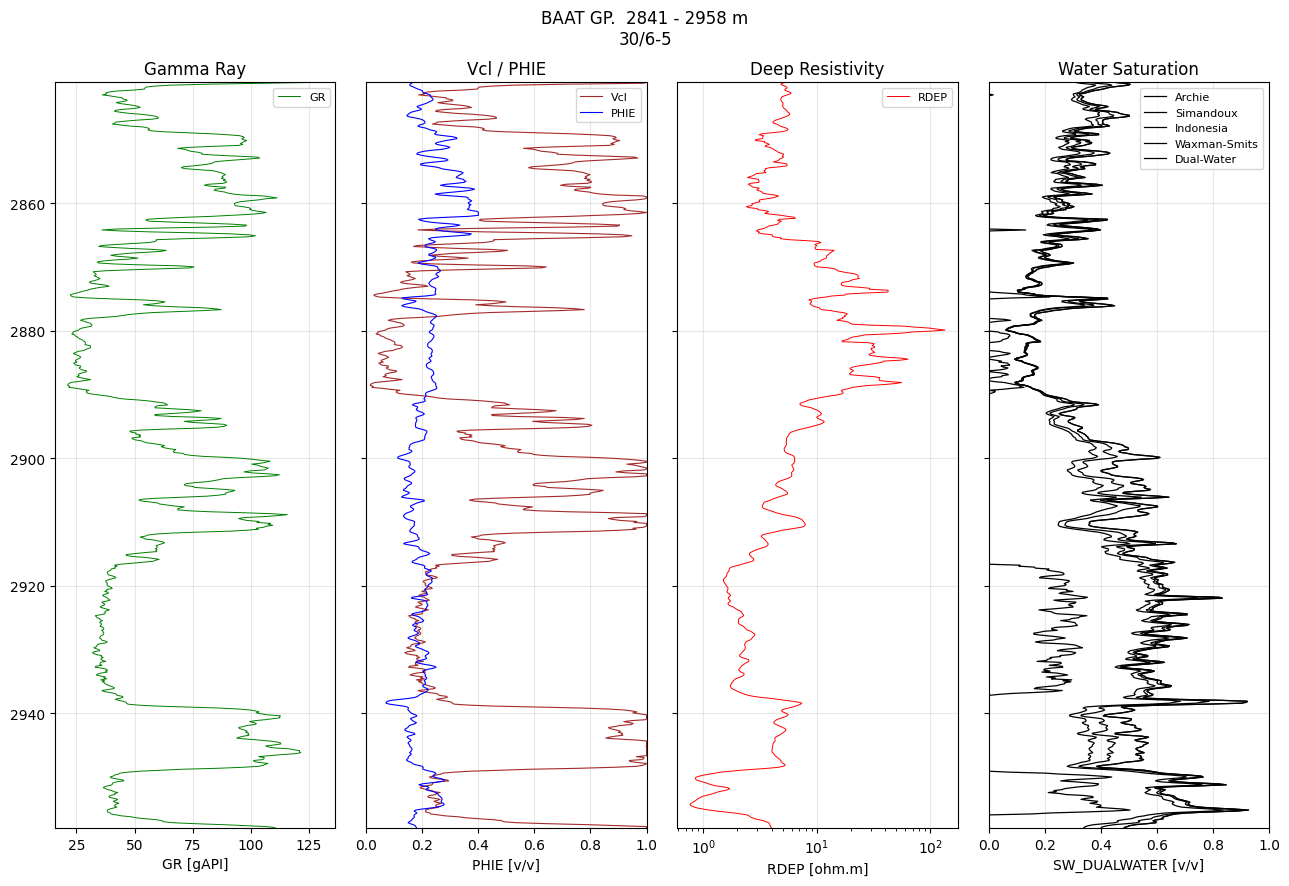

In [5]:
# Depth overlay via the library LogPlot. Attach the computed Vcl/PHIE and the
# five Sw models to the sliced reservoir well so LogPlot renders them on its grid.
from petrophys.visualization import LogPlot

res.add_curve('VCL',  vcl,  'v/v', 'Clay volume')
res.add_curve('PHIE', phie, 'v/v', 'Effective porosity')
res.add_curve('SW_ARCHIE',    sw_archie, 'v/v', 'Archie Sw')
res.add_curve('SW_SIMANDOUX', sw_sim,    'v/v', 'Simandoux Sw')
res.add_curve('SW_INDONESIA', sw_indo,   'v/v', 'Indonesia Sw')
res.add_curve('SW_WAXMAN',    sw_ws,     'v/v', 'Waxman-Smits Sw')
res.add_curve('SW_DUALWATER', sw_dw,     'v/v', 'Dual-Water Sw')

lp = LogPlot(res, figsize=(13, 9))
lp.create_figure(n_tracks=4)

lp.add_curve(0, 'GR', color='green', linewidth=0.7)
lp.axes[0].set_title('Gamma Ray')

lp.add_curve(1, 'VCL',  color='brown', linewidth=0.8, xlim=(0, 1), label='Vcl')
lp.add_curve(1, 'PHIE', color='blue',  linewidth=0.8, xlim=(0, 1), label='PHIE')
lp.axes[1].set_title('Vcl / PHIE')

lp.add_curve(2, 'RDEP', color='red', linewidth=0.7, log_scale=True)
lp.axes[2].set_title('Deep Resistivity')

for name, lab in [('SW_ARCHIE', 'Archie'), ('SW_SIMANDOUX', 'Simandoux'),
                  ('SW_INDONESIA', 'Indonesia'), ('SW_WAXMAN', 'Waxman-Smits'),
                  ('SW_DUALWATER', 'Dual-Water')]:
    lp.add_curve(3, name, linewidth=0.9, xlim=(0, 1), label=lab)
lp.axes[3].set_title('Water Saturation')

lp.add_title('BAAT GP.  %.0f - %.0f m' % (TOP, BASE))
lp.set_depth_range(TOP, BASE)
lp.show()

### A depth-zoned comparison table

Averages over the whole interval hide where the models agree and where they fight.
Let's tabulate the mean $S_w$ from each model over a **clean** sub-zone and a
**shaly** sub-zone (split on $V_{cl}$). The models should collapse onto Archie in
the clean rock and fan out in the shaly rock.

In [6]:
clean = vcl < 0.20
shaly = vcl >= 0.30

rows = []
for name, sw in [('Archie', sw_archie), ('Simandoux', sw_sim),
                 ('Indonesia', sw_indo), ('Waxman-Smits', sw_ws),
                 ('Dual-Water', sw_dw)]:
    rows.append({
        'Model'          : name,
        'Sw clean (Vcl<0.2)': round(float(np.nanmean(sw[clean])), 3),
        'Sw shaly (Vcl>0.3)': round(float(np.nanmean(sw[shaly])), 3),
        'Sw all'          : round(float(np.nanmean(sw)), 3),
    })

cmp_df = pd.DataFrame(rows).set_index('Model')
# Divergence from Archie in the shaly zone (percentage points of Sw)
cmp_df['delta vs Archie (shaly)'] = (
    cmp_df['Sw shaly (Vcl>0.3)'] - cmp_df.loc['Archie', 'Sw shaly (Vcl>0.3)']
).round(3)
print(cmp_df.to_string())

              Sw clean (Vcl<0.2)  Sw shaly (Vcl>0.3)  Sw all  delta vs Archie (shaly)
Model                                                                                
Archie                     0.340               0.417   0.426                    0.000
Simandoux                  0.331               0.360   0.389                   -0.057
Indonesia                  0.317               0.317   0.355                   -0.100
Waxman-Smits               0.339               0.416   0.425                   -0.001
Dual-Water                 0.129               0.000   0.067                   -0.417


### Interpreting the divergence

- **In clean rock** (`Vcl < 0.2`) every model sits close to Archie: with almost no
  clay, the correction terms vanish and the physics reduces to Archie. This is a
  good sanity check - if a shaly-sand model disagreed with Archie in clean rock,
  something would be wrong.
- **In shaly rock** (`Vcl > 0.3`) the models fan out. Archie is the most
  pessimistic (highest $S_w$); the corrections pull $S_w$ down by removing clay
  conductivity. The `delta vs Archie` column is a direct measure of how much
  hydrocarbon Archie would have missed.
- The **spread between the shaly-sand models themselves** is your uncertainty band.
  When they disagree strongly you are sensitive to $R_{cl}$, CEC, $R_{wb}$ - the
  parameters you know least well - and should calibrate against core or SCAL.

**Rule of thumb for picking a model** (this is exactly the logic `SaturationModule`
automates): clean -> Archie; shaly clastic with high salinity -> Simandoux; shaly
clastic with fresh water -> Indonesia; CEC/SCAL available -> Waxman-Smits;
carbonate or "just give me a robust default" -> Dual-Water.

## 5. The high-level driver: `calculate_sw`

You rarely wire up the models by hand. `calculate_sw(well, rw, a, m, n, model=...)`
reads the curves off the well and routes automatically (`model='auto'`) or forces
a single model. With `'auto'` it decides **sample by sample** using $V_{cl}$,
lithology and salinity, so one well can legitimately use several models across
depth. Here we run it in forced modes to reproduce our by-hand numbers, then in
auto mode.

In [7]:
from petrophys.petrophysics.saturation import calculate_sw

# Force Archie on the whole well, using our Rw. The driver reads RDEP and a
# porosity curve (PHIE_CC/PHIE) off the well; 30/6-5 has neither a VCL nor a
# PHIE curve stored, so we add PHIE to the sliced well for the demo.
res_demo = well.depth_slice(TOP, BASE)
res_demo.add_curve('PHIE', phie, 'v/v', 'Effective porosity (demo)')
res_demo.add_curve('VCL',  vcl,  'v/v', 'Clay volume (demo)')

sw_auto     = calculate_sw(res_demo, rw=RW, a=A, m=M, n=N, model='auto',
                           salinity=30000.0)
sw_forced_a = calculate_sw(res_demo, rw=RW, a=A, m=M, n=N, model='archie')

print('calculate_sw (forced archie) mean : %.3f' % np.nanmean(sw_forced_a))
print('calculate_sw (auto route)    mean : %.3f' % np.nanmean(sw_auto))
print()
print('For reference, our by-hand Archie mean : %.3f' % np.nanmean(sw_archie))

calculate_sw (forced archie) mean : 0.426
calculate_sw (auto route)    mean : 0.394

For reference, our by-hand Archie mean : 0.426


## 6. The Pickett plot - deriving $m$ (and $R_w$)

The Pickett plot is a log-log crossplot of **$R_t$ (x) vs porosity (y)**. Taking
logs of Archie for a **100% water** rock ($S_w=1$):

$$ \log R_t = -m\,\log\phi + \log(a\,R_w) $$

So on log-log axes the water-bearing points fall on a straight line whose
**slope is $-m$** and whose position fixes $a\,R_w$. Points that plot up and to
the right of that water line are hydrocarbon-bearing (higher $R_t$ at the same
porosity). `pickett_analysis(rt, phi, vcl=..., vcl_cutoff=...)` fits the clean
water line for us and returns an `ArchieParameters` object plus a stats dict.

**We need a water leg for a good fit.** The BAAT reservoir above is
hydrocarbon-bearing throughout, so its points sit *above* the water line and would
give a meaningless slope. Instead we use the deeper, low-resistivity
**Statfjord Fm sandstone (3223-3556 m)**, which is largely water-wet - its points
define a clean $S_w=1$ line.

In [8]:
from petrophys.petrophysics.cementation import pickett_analysis

# Load a water-bearing clean sand for the Pickett fit.
stat = well.depth_slice(3223.0, 3556.0)
gr_s   = stat.get('GR').data
rhob_s = stat.get('RHOB').data
nphi_s = stat.get('NPHI').data
rt_s   = stat.get('RDEP').data

vcl_s  = vcl_from_gr(gr_s, np.nanpercentile(gr_s, 5), np.nanpercentile(gr_s, 95))
phie_s = np.clip(
    (density_porosity(rhob_s) + neutron_porosity(nphi_s)) / 2.0, 0.0, 0.40)

# Fit the water line: regress log(Rt) on log(phi) over clean (Vcl<0.3) points.
params, stats = pickett_analysis(rt_s, phie_s, vcl=vcl_s, vcl_cutoff=0.3)
print('Derived cementation exponent m : %.2f' % params.m)
print('Fit R^2                        : %.3f' % stats['r_squared'])
print('N points used                  : %d'   % stats['n_points'])
print('Intercept log10(a*Rw)          : %.3f' % stats['intercept'])

# Recover an apparent Rw from the intercept (with a=1): intercept = log10(a*Rw)
rw_apparent = 10 ** stats['intercept']
print('Apparent a*Rw from intercept   : %.3f ohm.m' % rw_apparent)

Derived cementation exponent m : 1.15
Fit R^2                        : 0.849
N points used                  : 469
Intercept log10(a*Rw)          : -0.415
Apparent a*Rw from intercept   : 0.384 ohm.m


We can visualise the plot with a hand-drawn overlay so the geometry is explicit:
the fitted **water line** (slope $-m$) and parallel iso-$S_w$ lines above it. Colour
the points by their Archie $S_w$ so the water leg (blue-green, $S_w \to 1$) is
visibly the cluster that pins the line.

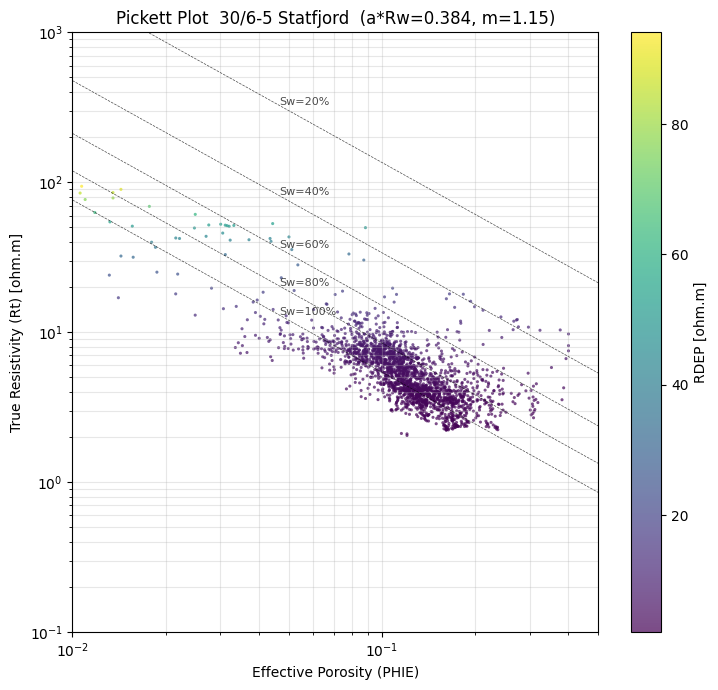

Points on/near the Sw=1 line are water; points to the right would be pay.


In [9]:
# Pickett plot via the library plotter. Attach PHIE to the water-bearing
# Statfjord slice (RDEP is already present) and let create_pickett_plot draw the
# log-log crossplot with Archie iso-Sw lines using the fitted m and apparent Rw.
from petrophys.visualization import create_pickett_plot

stat.add_curve('PHIE', phie_s, 'v/v', 'Effective porosity (Statfjord)')

pp = create_pickett_plot(stat, rw=rw_apparent, phie_curve='PHIE',
                         rt_curve='RDEP', color_curve='RDEP',
                         a=A, m=params.m, n=N, figsize=(7.5, 7))
pp.ax.set_title('Pickett Plot  30/6-5 Statfjord  (a*Rw=%.3f, m=%.2f)'
                % (rw_apparent, params.m))
pp.show()

print('Points on/near the Sw=1 line are water; points to the right would be pay.')

**How to use the derived $m$:** if the Pickett $m$ differs materially from your
assumed 2.0, feed it back into the saturation calculation. Here the fit returns an
$m$ well below 2.0 - a reminder that a *single* Pickett fit is only as good as the
water leg behind it: a limited porosity range, a thin water column, or residual
hydrocarbon points all bias the slope, so always sanity-check against expected
ranges (~1.8-2.0 for clean, well-connected sands; 2.2-2.8 for vuggy/moldic
carbonates) and against core-measured $m$ when available. The value here is a
teaching illustration of the method, not a production Archie parameter. Still, the
Pickett plot remains your first data-driven check on the number you would otherwise
just assume.

## 7. Flushed-zone saturation $S_{xo}$

Drilling mud filtrate invades the near-wellbore rock and flushes out moveable
hydrocarbon. The **flushed zone** therefore has its own water saturation $S_{xo}$,
computed with Archie but using the *shallow* resistivity $R_{xo}$ and the mud
filtrate resistivity $R_{mf}$:

$$ S_{xo}^{\,n} = \frac{a\,R_{mf}}{\phi^{m}\,R_{xo}} $$

`calculate_sxo(rxo, rmf, phi, a, m, n)` is Archie under the hood. Because
invasion sweeps moveable oil away, $S_{xo} \ge S_w$; the gap
$S_{xo}-S_w$ is a moveability indicator (more on that in notebook 09). 30/6-5 has a
shallow curve `RSHA`, so we can compute a real $S_{xo}$.

In [10]:
from petrophys.petrophysics.saturation import calculate_sxo

rxo = res.get('RSHA').data     # shallow (flushed-zone) resistivity
RMF = 0.05                     # mud-filtrate resistivity (illustrative), ohm.m

sxo = calculate_sxo(rxo, RMF, phie, a=A, m=M, n=N)

print('Sxo   mean : %.3f' % np.nanmean(sxo))
print('Sw    mean : %.3f  (Dual-Water)' % np.nanmean(sw_dw))
moveable = np.clip(sxo - sw_dw, 0, 1)
print('Sxo - Sw   : %.3f  (moveable-hydrocarbon indicator, mean)'
      % np.nanmean(moveable))
print()
print('A large positive Sxo-Sw means the mud pushed hydrocarbon out of the')
print('flushed zone -> the hydrocarbon was moveable (good news for producibility).')

Sxo   mean : 0.557
Sw    mean : 0.067  (Dual-Water)
Sxo - Sw   : 0.490  (moveable-hydrocarbon indicator, mean)

A large positive Sxo-Sw means the mud pushed hydrocarbon out of the
flushed zone -> the hydrocarbon was moveable (good news for producibility).


## 8. Carbonate model selection - Archie on a Costa well (HW-3)

Everything so far was a **clastic** North Sea sand. Carbonates behave differently:
they are usually **clean** (low $V_{cl}$), so the shaly-sand corrections are often
unnecessary - but their complex pore systems mean $m$ and $n$ drift away from 2 and
must be measured. The `petrophys` sample set includes a carbonate field ("Costa",
depths in feet). Well **HW-3** even carries its Archie parameters in the LAS
header, which we read with `well.get_parameter(...)`.

In [11]:
hw3 = read_las(petrophys.sample('HW-3'))
print('Well       :', hw3.name)
print('Depth unit :', hw3.depth_unit)
print('Curves     :', hw3.curves)
print()

# Read the Archie parameters straight from the header - do NOT assume 2.0.
rw_hw3 = hw3.get_parameter('RW')
a_hw3  = hw3.get_parameter('A')
m_hw3  = hw3.get_parameter('M')
n_hw3  = hw3.get_parameter('N')
print('Header Archie params : Rw=%.4f  a=%.2f  m=%.2f  n=%.2f'
      % (rw_hw3, a_hw3, m_hw3, n_hw3))

rt_hw3   = hw3.get('RT').data
phie_hw3 = hw3.get('PHIE_CC').data     # core-corrected effective porosity
gr_hw3   = hw3.get('GR').data
print()
print('GR range   : %.1f - %.1f gAPI  (very clean -> carbonate, Vcl ~ 0)'
      % (np.nanmin(gr_hw3), np.nanmax(gr_hw3)))

Well       : HW-3
Depth unit : ft
Curves     : ['GR', 'RHOB', 'NPHI', 'DT', 'PHIE_CC', 'RT', 'SW_INPUT', 'PERM_CC']

Header Archie params : Rw=0.0682  a=1.00  m=2.03  n=2.00

GR range   : 8.1 - 27.3 gAPI  (very clean -> carbonate, Vcl ~ 0)


In [12]:
# Carbonate is clean -> Archie is the right model, but with the header m=%.2f.
sw_hw3 = archie(rt_hw3, rw_hw3, phie_hw3, a=a_hw3, m=m_hw3, n=n_hw3)

# Compare against the well's own input saturation curve for a reality check.
sw_input = hw3.get('SW_INPUT').data

print('HW-3 Archie Sw (header m=%.2f) mean : %.3f'
      % (m_hw3, np.nanmean(sw_hw3)))
print('HW-3 stored SW_INPUT           mean : %.3f' % np.nanmean(sw_input))
print()

# What if we had naively used m=2.0 instead of the header value?
sw_naive = archie(rt_hw3, rw_hw3, phie_hw3, a=a_hw3, m=2.0, n=n_hw3)
print('HW-3 Archie Sw with naive m=2.0 mean : %.3f' % np.nanmean(sw_naive))
print('Effect of using the correct m        : %+.3f Sw'
      % (np.nanmean(sw_hw3) - np.nanmean(sw_naive)))

HW-3 Archie Sw (header m=2.03) mean : 0.299
HW-3 stored SW_INPUT           mean : 0.120

HW-3 Archie Sw with naive m=2.0 mean : 0.295
Effect of using the correct m        : +0.004 Sw


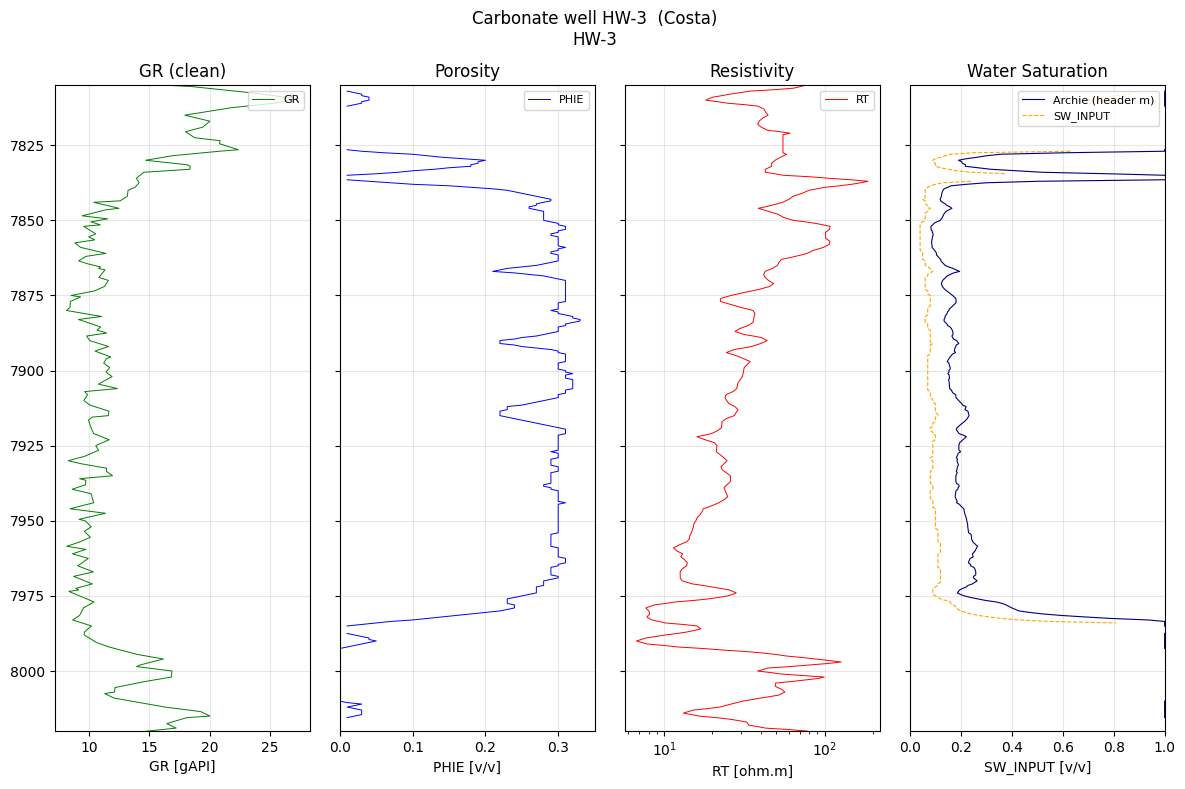

In [13]:
# Carbonate HW-3 depth overlay via the library LogPlot. Attach porosity and
# both saturation curves to the well; GR and RT are already present.
from petrophys.visualization import LogPlot

hw3.add_curve('PHIE',      phie_hw3, 'v/v', 'Core-corrected porosity')
hw3.add_curve('SW_ARCHIE', sw_hw3,   'v/v', 'Archie Sw (header m)')

lp = LogPlot(hw3, figsize=(12, 8))
lp.create_figure(n_tracks=4)

lp.add_curve(0, 'GR', color='green', linewidth=0.7)
lp.axes[0].set_title('GR (clean)')

lp.add_curve(1, 'PHIE', color='blue', linewidth=0.7, xlim=(0, 0.35))
lp.axes[1].set_title('Porosity')

lp.add_curve(2, 'RT', color='red', linewidth=0.7, log_scale=True)
lp.axes[2].set_title('Resistivity')

lp.add_curve(3, 'SW_ARCHIE', color='navy',   linewidth=0.8, xlim=(0, 1),
             label='Archie (header m)')
lp.add_curve(3, 'SW_INPUT',  color='orange', linewidth=0.8, linestyle='--',
             xlim=(0, 1), label='SW_INPUT')
lp.axes[3].set_title('Water Saturation')

lp.add_title('Carbonate well HW-3  (Costa)')
lp.set_depth_range()
lp.show()

### Clastic vs carbonate - which model, and why

| | Clastic (30/6-5) | Carbonate (HW-3) |
|---|---|---|
| Clay content | Variable, often high $V_{cl}$ | Very low $V_{cl}$ (clean) |
| Dominant $S_w$ problem | Clay conductivity | Complex/disconnected pore geometry |
| Model choice | Shaly-sand (Simandoux / Indonesia / Dual-Water) | **Archie**, but with measured $m, n$ |
| Key parameter to nail | $R_{cl}$, CEC, $R_{wb}$ | $m$ (cementation exponent), $n$ |
| Where the parameter comes from | Shale intervals, SCAL/CEC | Core / SCAL / Pickett; often in the LAS header |

The take-away: **the model is chosen by the rock, not by habit.** In clastics the
enemy is clay, so you spend your effort on shaly-sand corrections. In carbonates
the rock is clean but the pore system is wild, so you keep Archie and instead spend
your effort measuring $m$ and $n$ - which is exactly why HW-3 ships them in its
header. Using $m=2.0$ out of habit on a carbonate where $m=2.03$ (or 2.5) is
correct can shift $S_w$ enough to change a pay call.

## Pitfalls & parameter choices

- **$R_w$ dominates everything.** A 2x error in $R_w$ moves $S_w$ by roughly
  $\sqrt{2}$. Get it from an SP-derived $R_w$, a water-zone Pickett intercept, or a
  produced-water sample - not a guess.
- **Don't use a shaly-sand model in clean rock as insurance.** It won't hurt much,
  but if $R_{cl}$/CEC are poorly known it can add noise. Route on $V_{cl}$.
- **$m$ and $n$ are not universally 2.** Carbonates and cemented sands push $m$ up;
  oil-wet rocks push $n$ up. Both raise computed $S_w$. Measure them when the
  answer matters.
- **Waxman-Smits CEC is meq/g, not meq/100g.** Divide lab values by 100.
- **Dual-Water and Waxman-Smits use *total* porosity**, not effective. We passed
  our density-neutron porosity as a stand-in here; with a proper $\phi_t$ curve,
  use it.
- **$R_{cl}$ from shale**: estimating it from the shaliest samples (as we did) is a
  reasonable field trick, but a bad shale baseline propagates straight into $S_w$.

## Recap

- **Archie** is the clean-rock baseline: $S_w^n = a R_w / (\phi^m R_t)$.
- **Shaly-sand models** (Simandoux, Indonesia, Waxman-Smits, Dual-Water) remove
  clay conductivity and return **lower, less pessimistic** $S_w$; they converge on
  Archie in clean rock and diverge in shale.
- The **spread between models** is a direct read on parameter uncertainty.
- **`calculate_sw(model='auto')`** routes sample-by-sample so a well can mix models.
- The **Pickett plot** derives $m$ (and $R_w$) from the water line's slope and
  intercept - a data-driven alternative to assuming 2.0.
- **$S_{xo}$** (flushed zone) uses Archie with $R_{xo}, R_{mf}$; $S_{xo}-S_w$ flags
  moveable hydrocarbon.
- **Carbonates** stay on Archie but demand measured $m, n$; **clastics** demand
  shaly-sand corrections. The rock picks the model.

## Try it yourself

> **Exercise 1.** Re-run the model comparison with $R_w = 0.05$ instead of 0.03.
> How much does mean Archie $S_w$ change, and does the spread between shaly-sand
> models change too?
>
> **Exercise 2.** Take the Pickett-derived $m$ and recompute Archie $S_w$ with it.
> Compare to the $m=2.0$ result - is your pay interval bigger or smaller?
>
> **Exercise 3.** On HW-3, sweep $m$ from 1.8 to 2.6 and plot mean Archie $S_w$ vs
> $m$. This is the carbonate practitioner's core-calibration sensitivity in one
> chart.

## What's next

Continue with **08 - Permeability**, where we turn saturation and porosity into a
flow property using the Timur and Coates-Denoo estimators, and calibrate a
poro-perm transform against core data.